In [5]:
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u

Vizier.ROW_LIMIT = -1

v = Vizier(columns=["**"],row_limit=-1)
tables = v.get_catalogs("J/ApJ/614/167/table2")[0]
print("Rows returned:",len(tab))
pn = tables.to_pandas()

coords=SkyCoord(
    pn["RAJ2000"].astype(str).to_numpy(),
    pn["DEJ2000"].astype(str).to_numpy(),
    unit=(u.hourangle,u.deg),
    frame="icrs"
)

pn["RAdeg"] = coords.ra.deg
pn["DECdeg"] = coords.dec.deg

print(
    pn[["RAJ2000","DEJ2000","RAdeg","DECdeg"]]
    .head(10)
    .to_string(index=False)
)

pn.to_csv(
    "/Users/golta/Neb_det/data/PN_CAT_M33.csv",
    index=False
)

print("\nCoordinate ranges:")
print("RA :",pn["RAdeg"].min(),pn["RAdeg"].max())
print("Dec:",pn["DECdeg"].min(),pn["DECdeg"].max())
print("median:",pn["RAdeg"].median(),pn["DECdeg"].median())

pn.to_csv("M33_PN_CAT.csv", index=False)

Rows returned: 152
    RAJ2000     DEJ2000     RAdeg    DECdeg
01 32 09.04 +30 22 05.7 23.037667 30.368250
01 32 26.54 +30 25 49.8 23.110583 30.430500
01 32 38.03 +30 24 00.6 23.158458 30.400167
01 32 39.80 +30 37 41.0 23.165833 30.628056
01 32 40.08 +30 35 15.3 23.167000 30.587583
01 32 42.72 +30 12 25.5 23.178000 30.207083
01 32 44.29 +30 43 25.9 23.184542 30.723861
01 32 49.16 +30 51 09.1 23.204833 30.852528
01 32 52.96 +30 41 57.7 23.220667 30.699361
01 32 53.72 +30 32 25.8 23.223833 30.540500

Coordinate ranges:
RA : 23.037666666666663 23.806791666666665
Dec: 30.164694444444443 31.20836111111111
median: 23.469895833333332 30.655458333333332


In [6]:
from astropy.io import fits
from astropy.wcs import WCS
import numpy as np

MUSE_FILE="/Users/golta/Neb_det/data/M33_MAPS.fits"

with fits.open(MUSE_FILE,memmap=True) as hdul:
    hdul.info()

    for i,hdu in enumerate(hdul):
        if hdu.data is not None:
            print(
                i,
                hdu.header.get("EXTNAME"),
                hdu.data.shape,
                hdu.header.get("CTYPE1"),
                hdu.header.get("CTYPE2")
            )

Filename: /Users/golta/Neb_det/data/M33_MAPS.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      42   ()      
  1  ID            1 ImageHDU        25   (894, 2636)   float64   
  2  FLUX          1 ImageHDU        26   (894, 2636)   float64   
  3  SNR           1 ImageHDU        25   (894, 2636)   float64   
  4  SNRBIN        1 ImageHDU        25   (894, 2636)   float64   
  5  BIN_ID        1 ImageHDU        25   (894, 2636)   float64   
  6  V_STARS       1 ImageHDU        26   (894, 2636)   float64   
  7  FORM_ERR_V_STARS    1 ImageHDU        26   (894, 2636)   float64   
  8  SIGMA_STARS    1 ImageHDU        26   (894, 2636)   float64   
  9  FORM_ERR_SIGMA_STARS    1 ImageHDU        26   (894, 2636)   float64   
 10  H3_STARS      1 ImageHDU        25   (894, 2636)   float64   
 11  FORM_ERR_H3_STARS    1 ImageHDU        25   (894, 2636)   float64   
 12  H4_STARS      1 ImageHDU        25   (894, 2636)   float64   
 13  FORM

In [7]:
with fits.open(MUSE_FILE,memmap=True) as hdul:
    hdu=hdul["OIII5006_FLUX"]
    oiii=np.squeeze(np.asarray(hdu.data,dtype=float))
    wcs=WCS(hdu.header).celestial

ny,nx=oiii.shape

print("OIII shape:",oiii.shape)
print(wcs)

OIII shape: (2636, 894)
WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN' 'DEC--TAN'
CUNIT : 'deg' 'deg'
CRVAL : 23.462454565353 30.624825604782
CRPIX : 443.01217067058 2476.9594139807
PC1_1 PC1_2  : -5.1510214142599e-05 2.0811477411995e-05
PC2_1 PC2_2  : 2.0811477411995e-05 5.1510214142599e-05
CDELT : 1.0 1.0
NAXIS : 894  2636


/Users/golta/miniconda3/envs/tf311/lib/python3.11/site-packages/astropy/wcs/wcs.py:3237: RuntimeWarning: cdelt will be ignored since cd is present
  description.append(s.format(*self.wcs.cdelt))


In [8]:
from astropy.coordinates import SkyCoord
import astropy.units as u

corners=np.array([
    [0,0],
    [nx-1,0],
    [nx-1,ny-1],
    [0,ny-1],
])

corner_sky=wcs.pixel_to_world(corners[:,0],corners[:,1])

print("\nMUSE corners:")
for c in corner_sky:
    print(
        c.to_string(
            "hmsdms",
            precision=2
        )
    )

center=wcs.pixel_to_world(
    (nx-1)/2,
    (ny-1)/2
)

print("\nMUSE centre:")
print(center.to_string("hmsdms",precision=2))

print("\nMUSE centre degrees:")
print(center.ra.deg,center.dec.deg)


MUSE corners:
01h33m42.98s +30d29m17.11s
01h33m30.16s +30d30m23.92s
01h33m45.43s +30d38m32.65s
01h33m58.26s +30d37m25.74s

MUSE centre:
01h33m44.20s +30d33m54.88s

MUSE centre degrees:
23.434186302280406 30.565243478739276


In [9]:
x,y=wcs.world_to_pixel(coords)

pn["x"]=x
pn["y"]=y

inside=(
    np.isfinite(x)&np.isfinite(y)&
    (x>=0)&(x<nx)&
    (y>=0)&(y<ny)
)

print("\nTotal catalogue:",len(pn))
print("Inside rectangular WCS:",inside.sum())


Total catalogue: 152
Inside rectangular WCS: 9


In [10]:
cx=(nx-1)/2
cy=(ny-1)/2

pn["r_pix"]=np.hypot(pn["x"]-cx,pn["y"]-cy)

show=[
    "[CDL2004]",
    "RAJ2000",
    "DEJ2000",
    "RAdeg",
    "DECdeg",
    "x",
    "y",
    "r_pix"
]

show=[c for c in show if c in pn]

print(
    pn.sort_values("r_pix")[show]
    .head(20)
    .to_string(index=False)
)

 [CDL2004]     RAJ2000     DEJ2000     RAdeg    DECdeg           x           y       r_pix
        59 01 33 43.75 +30 33 26.6 23.432292 30.557389  420.801656 1175.404754  144.400359
        64 01 33 46.09 +30 33 35.8 23.442042 30.559944  297.890860 1274.640032  154.666265
        67 01 33 48.27 +30 33 15.7 23.451125 30.554361  129.706987 1234.176447  327.567745
        54 01 33 38.56 +30 33 02.3 23.410667 30.550639  686.168494  937.278837  449.454246
        69 01 33 49.36 +30 32 28.4 23.455667 30.541222  -24.149187 1041.258344  545.728971
        68 01 33 48.57 +30 35 47.9 23.452375 30.596639  396.753954 1947.046075  631.508455
        70 01 33 49.41 +30 32 06.6 23.455875 30.535167  -67.970124  941.402389  637.282451
        51 01 33 36.79 +30 31 40.5 23.403292 30.527917  639.171930  515.205551  825.105360
        78 01 33 54.68 +30 36 05.7 23.477833 30.601583   64.382179 2177.332615  940.917720
        47 01 33 32.21 +30 31 46.1 23.384208 30.529472  924.050495  430.500590 1007.383953

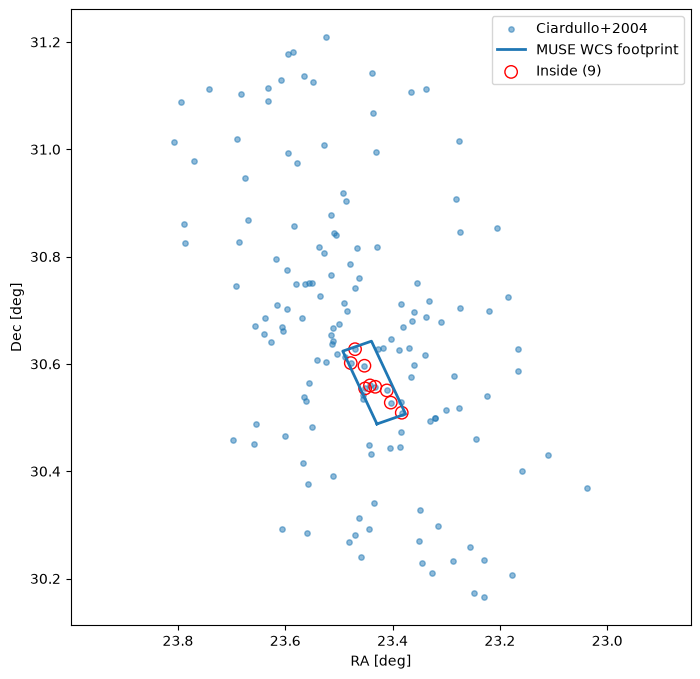

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,8))

plt.scatter(
    pn["RAdeg"],
    pn["DECdeg"],
    s=15,
    alpha=.5,
    label="Ciardullo+2004"
)

fp=wcs.calc_footprint()

plt.plot(
    np.r_[fp[:,0],fp[0,0]],
    np.r_[fp[:,1],fp[0,1]],
    lw=2,
    label="MUSE WCS footprint"
)

plt.scatter(
    pn.loc[inside,"RAdeg"],
    pn.loc[inside,"DECdeg"],
    s=80,
    facecolors="none",
    edgecolors="red",
    label=f"Inside ({inside.sum()})"
)

plt.gca().invert_xaxis()
plt.xlabel("RA [deg]")
plt.ylabel("Dec [deg]")
plt.legend()
plt.axis("equal")
plt.show()

In [12]:
inside_valid=np.zeros(len(pn),dtype=bool)

for i,(xx,yy) in enumerate(zip(x,y)):
    if not inside[i]:
        continue

    xi=int(round(xx))
    yi=int(round(yy))

    r=3
    cut=oiii[
        max(0,yi-r):min(ny,yi+r+1),
        max(0,xi-r):min(nx,xi+r+1)
    ]

    inside_valid[i]=np.any(np.isfinite(cut))

print("Inside WCS:",inside.sum())
print("On valid MUSE data:",inside_valid.sum())

Inside WCS: 9
On valid MUSE data: 8
